# EOD assignment, 3-fish recording

Recording `2024-10-15T14_12_25` (`data/3_fish_silent`), three fish in the tank; **the smallest fish (fish 0, SLEAP C) is the
emitter**, so every EOD should go to fish 0. Same model-pattern assignment as `EOD_assignment_ground_truth.ipynb` (2 fish),
restricted to frames that are good by both the masks and the SLEAP tracking, with:
- the electrode file of this recording, `data/electrodes/electrodes_signed_px_coord_3-fish.csv` (positions of 2024-02-13, pairs 2
  and 5 with + and − swapped, as found by the mirror-symmetry check in `electrode_polarity_check_3fish.ipynb`);
- two positions of the sink along the emitter's midline: at the tail tip, and 5% of the body length from it (`SINKS`);
- the shape-only comparison: each fish's model pattern and the recording each scaled to max |v| = 1 over the 10 pairs.

1. **Files**: what is in each file.
2. **Mask quality**: per-frame metrics on the ZEUS masks; frames where all three masks are clearly good.
3. **Frames good by masks and SLEAP**: intersection with `3_fish_good_frames_sleap.csv`; the EODs in those frames are assigned.
4. **Electric field per fish** (one example EOD).
5. **Assignment** of every EOD in the common frames: each fish in turn is the emitter (unit current, no length scaling, e = 0),
   for each sink position.
6. **Results**: % of EODs per fish, % correct (fish 0) against the distance to the other fish and over time, compared with the
   previous run (2024-02-13 electrode file, sink at the tail tip) and with Denis' pipeline.

Everything is saved in `OUT`: good frames, common frames, per-EOD QC status, model voltages, per-EOD assignments, fractions, figures.

In [1]:
import os, pickle, subprocess
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from scipy.ndimage import binary_dilation
import mask_metrics as mm                         # ZEUS crop unpacking + per-mask shape metrics (sets the Agg backend...)
%matplotlib inline
from scipy.spatial import cKDTree
from compute_electric_field import (mask_to_grid, multipole_sources, build_multipole_b, occupancy_field, build_A_shell,
                                    solve_potential, unflatten_to_grid, gammas)
from midline_methods import fish_midline_with_head
from eod_assign import load_electrode_pairs, peak_pattern, candidate_field, pair_voltages, compare_patterns, model_cache_tag

DATA = 'data/3_fish_silent'
EOD_CSV = f'{DATA}/Assigned_Data_3fish_2024-10-15T14_12_25.csv'
TRACK_PKL = f'{DATA}/elephantnose_20241015T141225_tracking_final.pkl'
VIDEO = f'{DATA}/video2024-10-15T14_12_25.avi'
TRACK_GOOD = 'results/eod_assignment_3_fish_silent/3_fish_good_frames_sleap.csv'   # frames with good SLEAP tracking
ELECTRODES_CSV = 'data/electrodes/electrodes_signed_px_coord_3-fish.csv'   # this recording's electrode file
REF_CSV = 'data/electrodes/electrodes_signed_px_coord_2024-02-13.csv'       # file of the previous run (same positions)
OUT = 'results/eod_ground_truth_3fish'
PREV_CACHE = 'results/eod_ground_truth_3fish/model_voltages_N150_sink0_elb898a3.pkl'   # previous run: 2024-02-13 file, sink at tip
os.makedirs(f'{OUT}/figures', exist_ok=True)

FISH, EMITTER = (0, 1, 2), 0                    # ZEUS labels: 1 = largest, 2 = second largest, 0 = smallest = the emitter
FISH_NAME = {0: 'fish 0 (smallest)', 1: 'fish 1 (largest)', 2: 'fish 2 (middle)'}
FISH_COLOR = {0: '#E0B000', 1: '#D45087', 2: '#2E8B57'}   # review-reel colours: yellow, pink, green

# mask quality thresholds (per fish and frame), as in the 2-fish notebook
AREA_TOL = 0.20                                 # area within 20% of that fish's median area
LENGTH_RANGE = (0.7, 1.2)                       # principal-axis length / that fish's median
MIN_LARGEST_FRAC = 0.99                         # >= 99% of the mask in one connected piece
MAX_STEP_PX = 15                                # centroid moves <= 15 px to the previous AND next frame
MAX_DAREA = 0.15                                # area changes <= 15% to the previous AND next frame
CONTACT_GAP = 5                                 # masks closer than 5 px count as touching

# field model (as in the 2-fish notebook)
N = 150                                         # tank grid resolution (N x N)
n_poles = 100                                   # n_poles + 1 point currents along each midline, tail -> head
delta_h = 0.5                                   # skin thickness, in grid-cell units
MAT = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6)
SINKS = (0.0, 0.05)                             # sink position: fraction of the body length from the tail tip
SINK_NAME = {0.0: 'sink at tail tip', 0.05: 'sink 5% from tail tip'}
N_WORKERS = 6                                   # parallel field solves

## 1. The files

### 1a. EOD table (`Assigned_Data_3fish_*.csv`)
One row per detected EOD: video `Frame`, time, SLEAP keypoints of fish A, B, C, an earlier pipeline's assignment
(`discharging_fish`, `similarity_*`), and 10 electrode pairs × 25 samples around the EOD peak (`electrode_<pair>_t_m12` … `t_p12`).

In [2]:
df_eod = pd.read_csv(EOD_CSV)
pair_cols = {int(c.split('_')[1]) for c in df_eod.columns if c.startswith('electrode_')}
trace_cols = {p: [c for c in df_eod.columns if c.startswith(f'electrode_{p}_t_')] for p in sorted(pair_cols)}
n_samp = len(trace_cols[1])
print(f"{len(df_eod)} EODs x {df_eod.shape[1]} columns ({len(trace_cols)} electrode pairs x {n_samp} samples)")
print(f"Frame {df_eod.Frame.min()}..{df_eod.Frame.max()} | RelativeTime {df_eod.RelativeTime.min():.2f}..{df_eod.RelativeTime.max():.0f} s "
      f"| {df_eod.Frame.nunique()} distinct frames, {(df_eod.Frame.value_counts() > 1).sum()} hold more than one EOD")
display(df_eod[['Frame', 'Time', 'RelativeTime', 'discharging_fish', 'head_x_A', 'head_y_A', 'head_score_A',
                'electrode_1_t_m12', 'electrode_1_t_0', 'electrode_1_t_p12']].head(3))

def recorded_pair_traces(row, pair_ids):
    '''(n_pairs, n_samp) recorded voltages of one df_eod row, each pair demeaned (eod_assign's, for this table's column names).'''
    V = np.stack([row[trace_cols[p]].to_numpy(float) for p in pair_ids])
    return V - np.nanmean(V, axis=1, keepdims=True)

19796 EODs x 309 columns (10 electrode pairs x 25 samples)
Frame 1..38580 | RelativeTime 0.02..772 s | 19583 distinct frames, 203 hold more than one EOD


,Frame,Time,RelativeTime,discharging_fish,head_x_A,head_y_A,head_score_A,electrode_1_t_m12,electrode_1_t_0,electrode_1_t_p12
0,1,2024-10-15 14:12:25.020,0.02,A,227.699646,128.205536,0.993362,-0.000336,-0.007190,-0.000133
1,1,2024-10-15 14:12:25.020,0.02,A,227.699646,128.205536,0.993362,-0.000318,-0.008492,-0.000353
2,1,2024-10-15 14:12:25.020,0.02,A,227.699646,128.205536,0.993362,-0.000411,-0.007712,-0.000244


### 1b. ZEUS masks (`*_tracking_final.pkl`)
One record per video frame: fish labels, bounding boxes, bit-packed mask crops. Frame k of the pickle is frame k of the AVI.

In [3]:
with open(TRACK_PKL, 'rb') as f:
    trk = pickle.load(f)
frames, fps, P = trk['frames'], trk['fps'], trk['shape'][0]
n_frames = len(frames)
print(trk['readme'][:300], '...')
print(f"labels: {trk['labels_key']}\ncolours: {trk['colour_key']}")
print("fish labels per frame:", pd.Series([tuple(sorted(l for l in fr['labels'] if l in FISH)) for fr in frames.values()]).value_counts().to_dict())

def frame_crops(k):
    '''{fish label: (box (y0, y1, x0, x1), bool crop)} of one tracked frame, remnant labels dropped.'''
    fr = frames[k]
    return {l: (b, mm.unpack_crop(p, b)) for l, p, b in zip(fr['labels'], fr['masks'], fr['boxes']) if l in FISH}

def frame_masks(k):
    '''(n_fish, P, P) full-frame bool masks of frame k, indexed by fish label (empty where a fish has no mask).'''
    m = np.zeros((len(FISH), P, P), bool)
    for l, ((y0, y1, x0, x1), c) in frame_crops(k).items():
        m[l, y0:y1, x0:x1] = c
    return m

ZEUS 3-fish identity tracking, recording three_fish_20241015T141225 (the AVI's frames up to the 60,000-frame cap, 912x912, 50 fps; frame k of the pickle is frame k of the AVI): 38863 frames at 50.0 fps, 912x912 px.

d["frames"][k] for frame k (0-based) holds one entry per tracked mask, aligned lists ...
labels: {1: 'largest fish', 2: 'second largest', 0: 'smallest fish', 3: 'not a fish (remnant)', 4: 'not a fish (remnant)', 5: 'not a fish (remnant)', 6: 'not a fish (remnant)'}
colours: {1: 'pink', 2: 'green', 0: 'yellow'}
fish labels per frame: {(0, 1, 2): 38799, (1, 2): 45, (0, 1): 19}


### 1c. Which SLEAP fish (A, B, C) is which mask?
Fraction of confident head and middle keypoints of each SLEAP fish lying on each mask, in the EOD frame (`Frame` = mask frame).

In [4]:
sub = df_eod.drop_duplicates('Frame').sample(500, random_state=0)
hits = pd.DataFrame(0.0, index=list('ABC'), columns=FISH); n_kp = pd.Series(0, index=list('ABC'))
for _, r in sub.iterrows():
    crops = frame_crops(int(r.Frame))
    for X in 'ABC':
        for p in ('head', 'middle'):
            if not r[f'{p}_score_{X}'] > 0.5: continue
            n_kp[X] += 1; x, y = int(round(r[f'{p}_x_{X}'])), int(round(r[f'{p}_y_{X}']))
            for l, ((y0, y1, x0, x1), c) in crops.items():
                if y0 <= y < y1 and x0 <= x < x1 and c[y - y0, x - x0]: hits.loc[X, l] += 1
hits = hits.div(n_kp, axis=0)
display(hits.round(2).rename(columns=lambda l: f'on mask {l}'))
SLEAP_TO_LABEL = hits.idxmax(axis=1).to_dict()
print('SLEAP fish -> mask label:', SLEAP_TO_LABEL)

,on mask 0,on mask 1,on mask 2
A,0.01,0.91,0.08
B,0.04,0.11,0.84
C,0.90,0.02,0.08


SLEAP fish -> mask label: {'A': 1, 'B': 2, 'C': 0}


### 1d. Electrodes and video
`electrodes_signed_px_coord_3-fish.csv`: the electrode positions of 2024-02-13 (they sit on the electrodes visible in this video),
with the polarity of pairs 2 and 5 swapped relative to that file (mirror-symmetry check: in this recording pairs 2 and 5 are reversed).

pairs with + and - swapped relative to data/electrodes/electrodes_signed_px_coord_2024-02-13.csv: [2, 5]


,pair,x1,y1,pol1,x2,y2,pol2
0,1,88,880,-,456,873,+
1,2,494,873,-,838,866,+
2,3,887,797,-,881,461,+
3,4,879,410,-,887,48,+
4,5,828,12,-,490,18,+
5,6,429,20,-,93,20,+
6,7,10,69,-,16,398,+
7,8,15,445,-,20,809,+
8,9,36,878,+,879,15,-
9,10,47,33,-,888,842,+


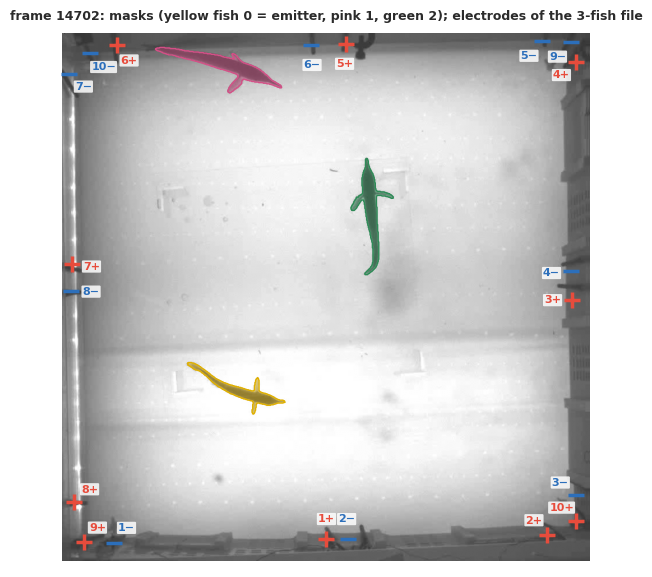

In [5]:
pairs = load_electrode_pairs(ELECTRODES_CSV, P)        # [(pair id, + point, - point)] in (row, col) / (P - 1)
pair_ids = [pid for pid, _, _ in pairs]
el, ref = pd.read_csv(ELECTRODES_CSV), pd.read_csv(REF_CSV)
assert (el[['x1', 'y1', 'x2', 'y2']].to_numpy() == ref[['x1', 'y1', 'x2', 'y2']].to_numpy()).all()   # same positions
FLIPPED = el.pair[el.pol1 != ref.pol1].tolist()
print(f"pairs with + and - swapped relative to {REF_CSV}: {FLIPPED}")
display(el)

def video_frame(k, path=VIDEO):
    '''Grayscale (P, P) frame k of the raw video (needs ffmpeg).'''
    out = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{k / fps:.4f}', '-i', path, '-frames:v', '1',
                          '-f', 'rawvideo', '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.uint8).reshape(P, P)

def draw_tank(ax, k):
    '''Video frame k with the fish masks (filled) and the electrodes (+ red, - blue, labelled by pair).'''
    ax.imshow(video_frame(k), cmap='gray')
    fm, over = frame_masks(k), np.zeros((P, P, 4))
    for f in FISH:
        over[fm[f]] = to_rgba(FISH_COLOR[f], 0.45)
        if fm[f].any(): ax.contour(fm[f], levels=[0.5], colors=[FISH_COLOR[f]], linewidths=1)
    ax.imshow(over)
    for pid, pp, pm in pairs:
        for pt, sgn, col, mk in ((pp, '+', '#E74C3C', '+'), (pm, '−', '#2C6FBB', '_')):
            y, x = pt * (P - 1)
            ax.plot(x, y, mk, color=col, ms=11, mew=2.5)
            off = np.array([P / 2 - x, P / 2 - y]); off = 34 * off / np.linalg.norm(off)
            ax.text(x + off[0], y + off[1], f'{pid}{sgn}', color=col, fontsize=8, fontweight='bold', ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.85))
    ax.set(xlim=(-10, P + 10), ylim=(P + 10, -10)); ax.set_axis_off()

k = int(df_eod.Frame.iloc[len(df_eod) // 2])
fig, ax = plt.subplots(figsize=(7, 7))
draw_tank(ax, k)
ax.set_title(f'frame {k}: masks (yellow fish 0 = emitter, pink 1, green 2); electrodes of the 3-fish file', fontsize=9)
fig.savefig(f'{OUT}/figures/tank_example.png', dpi=110, bbox_inches='tight'); plt.show()

## 2. Mask quality

Per fish and frame (all frames), a mask passes when:

| check | why |
|---|---|
| exactly one mask with that label, no remnant masks in the frame | no split or duplicated fish |
| area within 20% of that fish's median area | not cut or merged |
| principal-axis length 0.7–1.2 × that fish's median | not truncated or fused |
| ≥ 99% of the mask in one connected piece | no stray pieces |
| centroid step ≤ 15 px and area change ≤ 15% to the previous and the next frame | no identity jump or flicker |
| not within 5 px of any other fish | head side and body outline are reliable |

A frame is good when all three fish pass every check.

fish,fish 0: % frames passing,fish 1: % frames passing,fish 2: % frames passing
"one mask, no remnants",100.0,100.0,100.0
area within 20% of median,85.5,95.5,94.8
length 0.7-1.2 x median,85.7,98.9,99.1
>= 99% in one piece,97.0,96.1,94.5
step <= 15 px,96.9,99.8,99.7
area change <= 15%,98.6,99.4,99.4
not touching other fish,91.7,62.9,63.8
all,71.6,60.3,62.4


good frames (all three fish pass every check): 17392 / 38863 (44.8%) -> results/eod_ground_truth_3fish/good_frames.csv


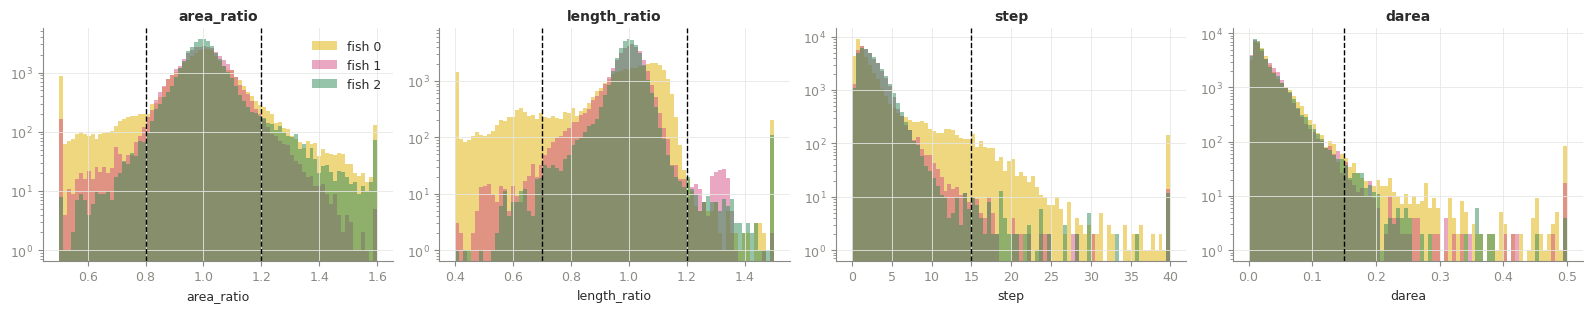

In [6]:
def in_contact(a, b, gap=CONTACT_GAP):
    '''True if two (box, crop) masks come within `gap` px (8-neighbour steps) of each other.'''
    (ba, ca), (bb, cb) = a, b
    if max(ba[0] - bb[1], bb[0] - ba[1], ba[2] - bb[3], bb[2] - ba[3]) > gap: return False   # boxes far apart
    y0, x0 = min(ba[0], bb[0]) - gap, min(ba[2], bb[2]) - gap
    win = np.zeros((2, max(ba[1], bb[1]) + gap - y0, max(ba[3], bb[3]) + gap - x0), bool)
    for w, ((r0, r1, c0, c1), c) in zip(win, (a, b)): w[r0 - y0:r1 - y0, c0 - x0:c1 - x0] = c
    return bool((binary_dilation(win[0], np.ones((3, 3)), iterations=gap) & win[1]).any())

rows = []
for k in range(n_frames):
    labels, crops = frames[k]['labels'], frame_crops(k)
    for l, (box, crop) in crops.items():
        rows.append(dict(frame=k, fish=l, n_masks=labels.count(l), n_remnant=sum(x not in FISH for x in labels),
                         contact=any(in_contact(crops[l], crops[o]) for o in crops if o != l), **mm.shape_metrics(crop, box)))
q = pd.DataFrame(rows)

for f in FISH:                                  # temporal stability, worst of the previous and next frame
    s = q[q.fish == f].set_index('frame').reindex(range(n_frames))
    step = np.hypot(s.cx.diff(), s.cy.diff())
    darea = (s.px / s.px.shift(1) - 1).abs()
    q.loc[q.fish == f, 'step'] = np.fmax(step, step.shift(-1)).fillna(np.inf).loc[q.frame[q.fish == f]].to_numpy()
    q.loc[q.fish == f, 'darea'] = np.fmax(darea, darea.shift(-1)).fillna(np.inf).loc[q.frame[q.fish == f]].to_numpy()
med = q.groupby('fish')[['px', 'major']].transform('median')
q['area_ratio'], q['length_ratio'] = q.px / med.px, q.major / med.major

checks = pd.DataFrame({
    'one mask, no remnants': (q.n_masks == 1) & (q.n_remnant == 0),
    f'area within {AREA_TOL:.0%} of median': (q.area_ratio - 1).abs() <= AREA_TOL,
    f'length {LENGTH_RANGE[0]}-{LENGTH_RANGE[1]} x median': q.length_ratio.between(*LENGTH_RANGE),
    f'>= {MIN_LARGEST_FRAC:.0%} in one piece': q.largest_frac >= MIN_LARGEST_FRAC,
    f'step <= {MAX_STEP_PX} px': q.step <= MAX_STEP_PX,
    f'area change <= {MAX_DAREA:.0%}': q.darea <= MAX_DAREA,
    'not touching other fish': ~q.contact,
})
checks['all'] = checks.all(axis=1)
display((checks.groupby(q.fish).mean().T * 100).round(1).rename(columns=lambda f: f'fish {f}: % frames passing'))

per_frame = checks['all'].groupby(q.frame).agg(['all', 'size'])
good_frames = per_frame.index[per_frame['all'] & (per_frame['size'] == len(FISH))].to_numpy()
pd.Series(good_frames, name='frame').to_csv(f'{OUT}/good_frames.csv', index=False)
print(f"good frames (all three fish pass every check): {len(good_frames)} / {n_frames} ({len(good_frames) / n_frames:.1%}) "
      f"-> {OUT}/good_frames.csv")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, col, lim, thr in zip(ax, ['area_ratio', 'length_ratio', 'step', 'darea'],
                            [(0.5, 1.6), (0.4, 1.5), (0, 40), (0, 0.5)],
                            [(1 - AREA_TOL, 1 + AREA_TOL), LENGTH_RANGE, (MAX_STEP_PX,), (MAX_DAREA,)]):
    for f in FISH:
        a.hist(q.loc[q.fish == f, col].clip(*lim), bins=80, range=lim, alpha=0.5, color=FISH_COLOR[f], label=f'fish {f}')
    for t in thr: a.axvline(t, color='k', ls='--', lw=1)
    a.set(xlabel=col, yscale='log', title=col)
ax[0].legend(); plt.tight_layout(); fig.savefig(f'{OUT}/figures/mask_qc.png', dpi=110); plt.show()

## 3. Frames good by both the masks and the SLEAP tracking
`TRACK_GOOD` lists the EOD frames whose SLEAP keypoints are good. The assignment runs on every EOD whose frame passes the mask QC
and is in that list.

In [7]:
track_good = pd.read_csv(TRACK_GOOD)
common = np.intersect1d(good_frames, track_good.Frame)
pd.Series(common, name='frame').to_csv(f'{OUT}/common_good_frames.csv', index=False)
ev = df_eod[df_eod.Frame.isin(common)]

summary = pd.DataFrame({'frames': [n_frames, len(good_frames), track_good.Frame.nunique(), len(common)],
                        'EODs': [len(df_eod), df_eod.Frame.isin(good_frames).sum(), df_eod.Frame.isin(track_good.Frame).sum(), len(ev)]},
                       index=['all', 'mask QC good', 'SLEAP good', 'both (analysed)'])
summary['% frames'] = 100 * summary.frames / n_frames
summary['% EODs'] = 100 * summary.EODs / len(df_eod)
summary.to_csv(f'{OUT}/frame_eod_summary.csv')
display(summary.round(2))

status = pd.DataFrame({'Frame': df_eod.Frame, 'RelativeTime': df_eod.RelativeTime,
                       'in_good_frame': df_eod.Frame.isin(good_frames), 'sleap_good': df_eod.Frame.isin(track_good.Frame),
                       'analysed': df_eod.index.isin(ev.index)})
status.to_csv(f'{OUT}/eod_qc_status.csv', index_label='row')
print(f"saved {OUT}/common_good_frames.csv, {OUT}/eod_qc_status.csv, {OUT}/frame_eod_summary.csv")

,frames,EODs,% frames,% EODs
all,38863,19796,100.00,100.00
mask QC good,17392,9332,44.75,47.14
SLEAP good,9731,9846,25.04,49.74
both (analysed),6879,6938,17.70,35.05


saved results/eod_ground_truth_3fish/common_good_frames.csv, results/eod_ground_truth_3fish/eod_qc_status.csv, results/eod_ground_truth_3fish/frame_eod_summary.csv


## 4. Electric field of each candidate fish (one example EOD)

Each fish in turn emits unit current along its midline (`candidate_field`: sink 5% of the body length from the tail tip, sources
spread over the rest of the body towards the head, head from the area rule); the other two fish are passive bodies (skin +
interior). Resistive (ω = 0) solve on an N × N grid, sampled at the electrodes.

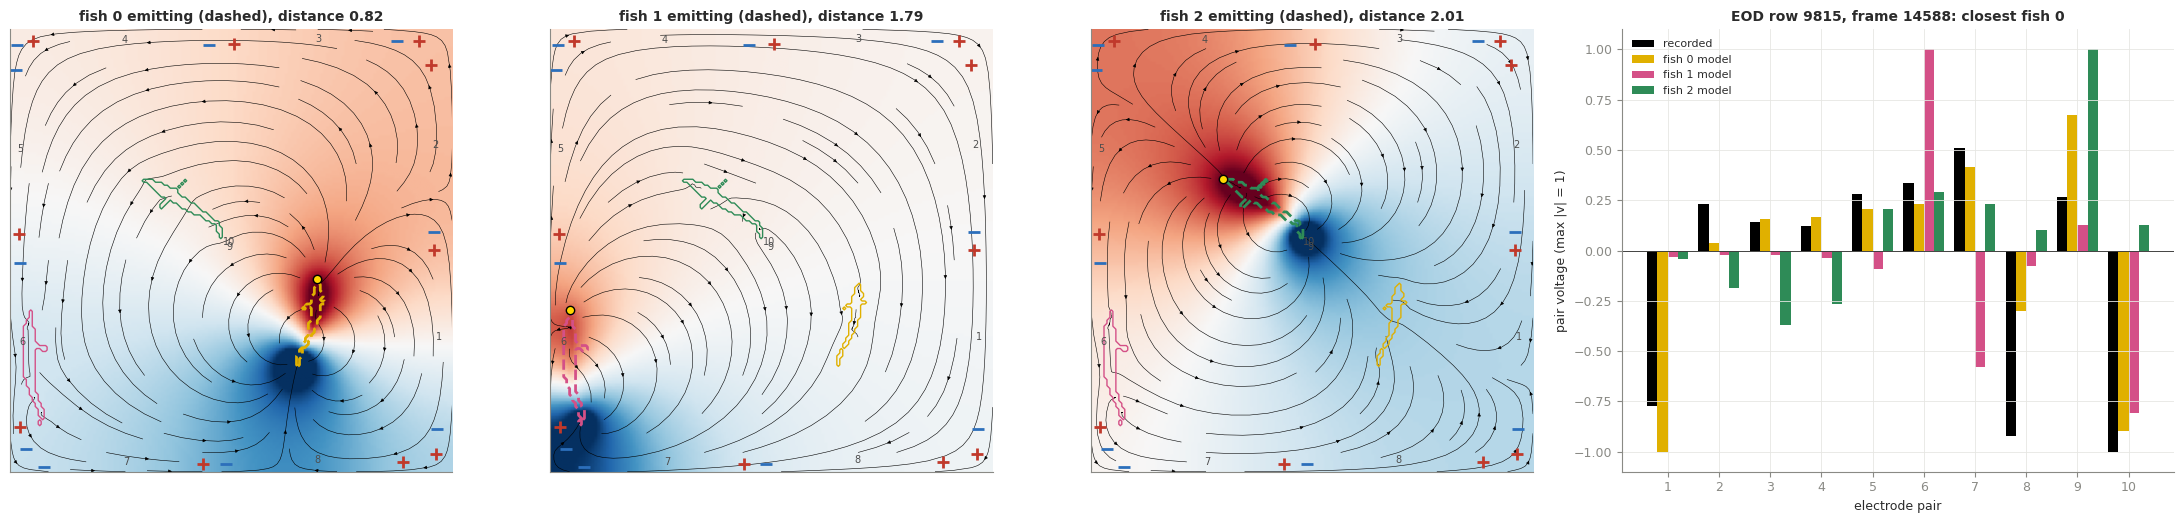

In [8]:
def frame_midlines(fm):
    '''Midline (n_poles + 1, 2) in tank coords, tail -> head, of every fish in a (n_fish, P, P) mask stack.'''
    return [fish_midline_with_head(m, n_ctrl=n_poles + 1)['midline'] for m in fm]

row = ev.iloc[len(ev) // 2]; k = int(row.Frame)
fm = frame_masks(k); mids = frame_midlines(fm)
phis = [candidate_field(fm, f, mids[f], N, delta_h, MAT).real for f in FISH]
r, _ = peak_pattern(recorded_pair_traces(row, pair_ids))
cmp = [compare_patterns(pair_voltages(phi, pairs, N), r) for phi in phis]          # (distance, model scaled, recording scaled)

g, h = np.linspace(0, 1, N), 1.0 / (N - 1)
fig, ax = plt.subplots(1, 4, figsize=(22, 5.3), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.2]))
for f in FISH:
    Ex, Ey = (-d for d in np.gradient(phis[f], h))
    v = np.percentile(np.abs(phis[f]), 99)
    ax[f].imshow(phis[f].T, origin='lower', extent=[0, 1, 0, 1], cmap='RdBu_r', vmin=-v, vmax=v)
    ax[f].streamplot(g, g, Ex.T, Ey.T, color='k', density=0.8, linewidth=0.4, arrowsize=0.5)
    for l in FISH:
        ax[f].contour(g, g, mask_to_grid(fm[l], N).T.astype(float), levels=[0.5], colors=[FISH_COLOR[l]],
                      linewidths=2 if l == f else 1, linestyles='--' if l == f else '-')
    ax[f].plot(*mids[f][-1], 'o', color='gold', mec='k', ms=6)
    for pid, pp, pm in pairs:
        ax[f].plot(*pp, '+', color='#C0392B', ms=8, mew=2); ax[f].plot(*pm, '_', color='#2C6FBB', ms=8, mew=2)
        ax[f].text(*(0.5 * (pp + pm)), str(pid), fontsize=7, color='0.3')
    ax[f].set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xticks=[], yticks=[],
              title=f'fish {f} emitting (dashed), distance {cmp[f][0]:.2f}')
x, w = np.arange(len(pair_ids)), 0.2
ax[3].bar(x - 1.5 * w, cmp[0][2], w, color='k', label='recorded')
for j, f in enumerate(FISH):
    ax[3].bar(x + (j - 0.5) * w, cmp[f][1], w, color=FISH_COLOR[f], label=f'fish {f} model')
ax[3].axhline(0, color='k', lw=0.5)
ax[3].set(xticks=x, xticklabels=pair_ids, xlabel='electrode pair', ylabel='pair voltage (max |v| = 1)',
          title=f'EOD row {row.name}, frame {k}: closest fish {int(np.argmin([c[0] for c in cmp]))}')
ax[3].legend(fontsize=8); plt.tight_layout(); fig.savefig(f'{OUT}/figures/field_example.png', dpi=110); plt.show()

## 5. Assigning the EODs (model-pattern match, shape only)

For every EOD in the common frames and each candidate emitter: the conductance matrix of the tank with the two other fish as bodies is
built once and solved for both source layouts of `SINKS` (`multipole_sources(..., sink_frac=s)`: sink −1 at that fraction of the body
length from the tail tip, +1 spread over the points from there to the head), then sampled at the electrodes. `N_WORKERS` parallel
processes; the voltages are cached per EOD in `OUT`.

**Shape only** (`eod_assign.assign_eod`'s rule): each fish's 10 model pair voltages scaled to max |v| = 1, the recording scaled to max
|v| = 1, L2 distance with the model's sign free; the fish with the smallest distance gets the EOD.

In [9]:
gw, gs, gi = gammas(0.0, **MAT)

def model_voltages(i):
    '''Recorded peak pattern and, per sink position, the unit-current pair voltages (n_fish, n_pairs) for EOD row i.'''
    row = df_eod.loc[i]; fm = frame_masks(int(row.Frame)); mids = frame_midlines(fm)
    u = {s: [] for s in SINKS}
    for f in FISH:
        A = build_A_shell(occupancy_field(fm, N, skip=f), N, delta_h, gw, gs, gi)     # the same for every sink position
        for s in SINKS:
            b = build_multipole_b(*multipole_sources(mids[f], I0=1.0, sink_frac=s), h, N)
            u[s].append(pair_voltages(unflatten_to_grid(solve_potential(A, b), N).real, pairs, N))
    return dict(row=i, frame=int(row.Frame), time=row.RelativeTime, v_rec=peak_pattern(recorded_pair_traces(row, pair_ids))[0],
                L=np.array([np.linalg.norm(np.diff(m, axis=0), axis=1).sum() for m in mids]),
                **{f'u_sink{s:g}': np.array(u[s]) for s in SINKS})

EL_TAG = model_cache_tag(N, ELECTRODES_CSV).split('_el')[1]
CACHE = f"{OUT}/model_voltages_N{N}_sinks{'and'.join(f'{s:g}' for s in SINKS)}_el{EL_TAG}.pkl"   # per EOD row
cache = pd.read_pickle(CACHE) if os.path.exists(CACHE) else None
todo = list(ev.index if cache is None else ev.index.difference(cache.index))
print(f"{len(ev) - len(todo)} of {len(ev)} EODs loaded from {CACHE}, {len(todo)} to solve")
out = []
def save(cache, out):
    new = pd.DataFrame(out).set_index('row')
    cache = new if cache is None else pd.concat([cache, new])
    cache.to_pickle(CACHE); return cache
with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:     # forked workers share the loaded masks
    for n, o in enumerate(pool.map(model_voltages, todo, chunksize=4)):
        out.append(o)
        if (n + 1) % 500 == 0:
            cache, out = save(cache, out), []; print(f"{n + 1}/{len(todo)} EODs (cached)")
if out: cache = save(cache, out)
res = cache.loc[ev.index].copy()
R = np.stack(res.v_rec)                                          # recorded (n, n_pairs)
U = {s: np.stack(res[f'u_sink{s:g}']) for s in SINKS}             # unit-current model (n, n_fish, n_pairs)

# checks: sink 5% = candidate_field (multipole_sources' default); sink at the tip = previous run with pairs 2 and 5 negated
i0 = res.index[0]; fm0 = frame_masks(int(res.frame[i0])); mids0 = frame_midlines(fm0)
assert np.allclose(U[0.05][0], [pair_voltages(candidate_field(fm0, f, mids0[f], N, delta_h, MAT).real, pairs, N) for f in FISH])
prev = pd.read_pickle(PREV_CACHE).loc[res.index]
flip = np.where(np.isin(pair_ids, FLIPPED), -1.0, 1.0)
U_prev = np.stack(prev['u_2024-02-13'])                           # previous run: 2024-02-13 labels, sink at the tail tip
assert np.allclose(U[0.0], U_prev * flip) and np.allclose(R, np.stack(prev.v_rec))
print(f"checks passed: sink 5% = candidate_field; sink at the tip = previous run's voltages with pairs {FLIPPED} negated")

6938 of 6938 EODs loaded from results/eod_ground_truth_3fish/model_voltages_N150_sinks0and0.05_elc5c81b.pkl, 0 to solve


checks passed: sink 5% = candidate_field; sink at the tip = previous run's voltages with pairs [2, 5] negated


In [10]:
def shape_assign(M):
    '''assign_eod's rule on model voltages M (n, n_fish, n_pairs): L2 distance of the peak-normalized patterns, minimized over
       the model's sign; the smallest distance wins. Returns (fish (n,), distances (n, n_fish)).'''
    D = np.array([[compare_patterns(m, r)[0] for m in Ms] for Ms, r in zip(M, R)])
    return D.argmin(axis=1), D

VARIANTS = {f'3-fish electrodes, {SINK_NAME[s]}': U[s] for s in SINKS}
VARIANTS['previous run: 2024-02-13 electrodes, sink at tail tip'] = U_prev
assigned = res[['frame', 'time']].copy()
for name, M in VARIANTS.items():
    fish, D = shape_assign(M)
    assigned[f'fish | {name}'] = fish
    for f in FISH: assigned[f'distance fish {f} | {name}'] = D[:, f]
# Denis' latest run (../EODAssignment analysis/notebooks/3fish-silent-assign-eods.ipynb, commit 285934d): 3-fish electrode file,
# no refractory step, same rows as Assigned_Data_3fish_...csv; its A/B/C are by length (A longest), C = the smallest = fish 0
denis = pd.read_csv('results/eod_assignment_3_fish_silent/eod_assignment_summary.csv')
assert len(denis) == len(df_eod) and (denis.Frame.to_numpy() == df_eod.Frame.to_numpy()).all()
assigned["fish | Denis' pipeline (3-fish electrodes, latest run)"] = denis.loc[res.index, 'discharging_fish'].map({'A': 1, 'B': 2, 'C': 0})
fish_cols = [c for c in assigned.columns if c.startswith('fish |')]

## 6. Results

Fish 0 (the smallest fish, SLEAP C) is the emitter, so % fish 0 is the % of EODs assigned correctly. All rows use the same EODs.

,n EODs,fish 0 (smallest),fish 1 (largest),fish 2 (middle)
pipeline,,,,
"3-fish electrodes, sink at tail tip",6938,89.48,3.47,7.05
"3-fish electrodes, sink 5% from tail tip",6938,87.55,4.11,8.35
"previous run: 2024-02-13 electrodes, sink at tail tip",6938,83.78,6.07,10.15
"Denis' pipeline (3-fish electrodes, latest run)",6938,93.89,2.36,3.75


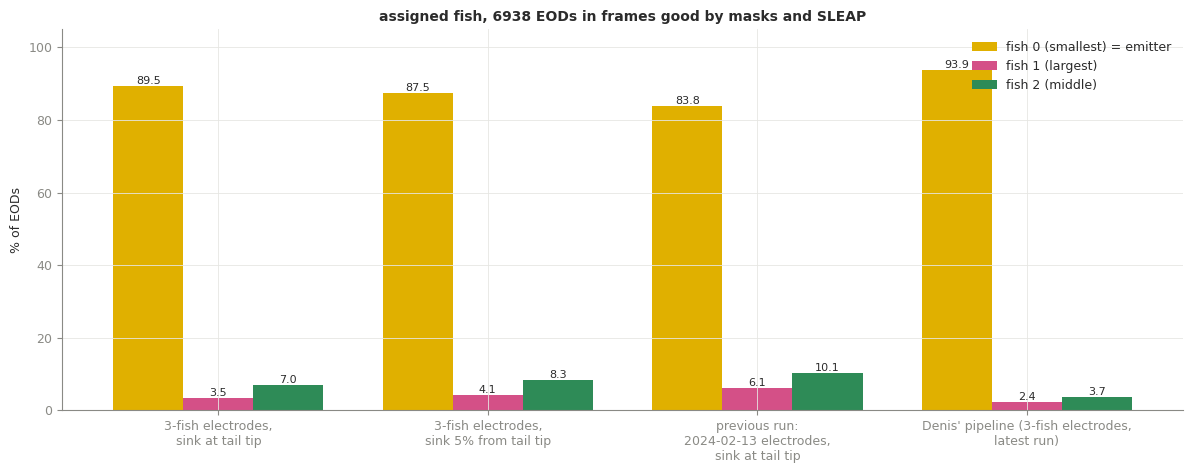

In [11]:
frac = pd.DataFrame({c.replace('fish | ', ''): assigned[c].value_counts(normalize=True).reindex(FISH, fill_value=0) * 100
                     for c in fish_cols}).T.rename(columns=FISH_NAME)
frac.insert(0, 'n EODs', len(assigned))
frac.index.name = 'pipeline'
frac.to_csv(f'{OUT}/assignment_fractions_my_pipeline.csv')
display(frac.round(2))

fig, ax = plt.subplots(figsize=(12, 4.8))
x, w = np.arange(len(frac)), 0.26
for j, f in enumerate(FISH):
    bars = ax.bar(x + (j - 1) * w, frac[FISH_NAME[f]], w, color=FISH_COLOR[f],
                  label=FISH_NAME[f] + (' = emitter' if f == EMITTER else ''))
    ax.bar_label(bars, fmt='%.1f', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([t.replace(': ', ':\n').replace(', ', ',\n', 1) for t in frac.index], fontsize=9)
ax.set(ylabel='% of EODs', ylim=(0, 105), title=f'assigned fish, {len(assigned)} EODs in frames good by masks and SLEAP')
ax.legend(fontsize=9, loc='upper right'); plt.tight_layout(); fig.savefig(f'{OUT}/figures/assignment_fractions.png', dpi=110); plt.show()

### Agreement between the pipelines

% of EODs given the same fish by each pair of pipelines, and the cross-table of the two sink positions.

In [12]:
names = [c.replace('fish | ', '') for c in fish_cols]
agree = pd.DataFrame([[100 * (assigned[a] == assigned[b]).mean() for b in fish_cols] for a in fish_cols], index=names, columns=names)
display(agree.round(1))
s0, s5 = (f'fish | 3-fish electrodes, {SINK_NAME[s]}' for s in SINKS)
display(pd.crosstab(assigned[s0].rename(SINK_NAME[0.0]), assigned[s5].rename(SINK_NAME[0.05]), margins=True))

,"3-fish electrodes, sink at tail tip","3-fish electrodes, sink 5% from tail tip","previous run: 2024-02-13 electrodes, sink at tail tip","Denis' pipeline (3-fish electrodes, latest run)"
"3-fish electrodes, sink at tail tip",100.0,97.2,92.2,91.7
"3-fish electrodes, sink 5% from tail tip",97.2,100.0,91.0,90.8
"previous run: 2024-02-13 electrodes, sink at tail tip",92.2,91.0,100.0,86.2
"Denis' pipeline (3-fish electrodes, latest run)",91.7,90.8,86.2,100.0


sink 5% from tail tip,0,1,2,All
sink at tail tip,,,,
0,6046,54,108,6208
1,6,230,5,241
2,22,1,466,489
All,6074,285,579,6938


### % correct against the distance between the emitter and the other fish

Distance = smallest distance (px, mask edge to edge) between fish 0 and the nearer of the two other fish in the EOD's frame; 10 bins with
equal numbers of EODs; error bars: 95% Wilson interval.

6938 EODs -> results/eod_ground_truth_3fish/eod_assignments_my_pipeline.csv


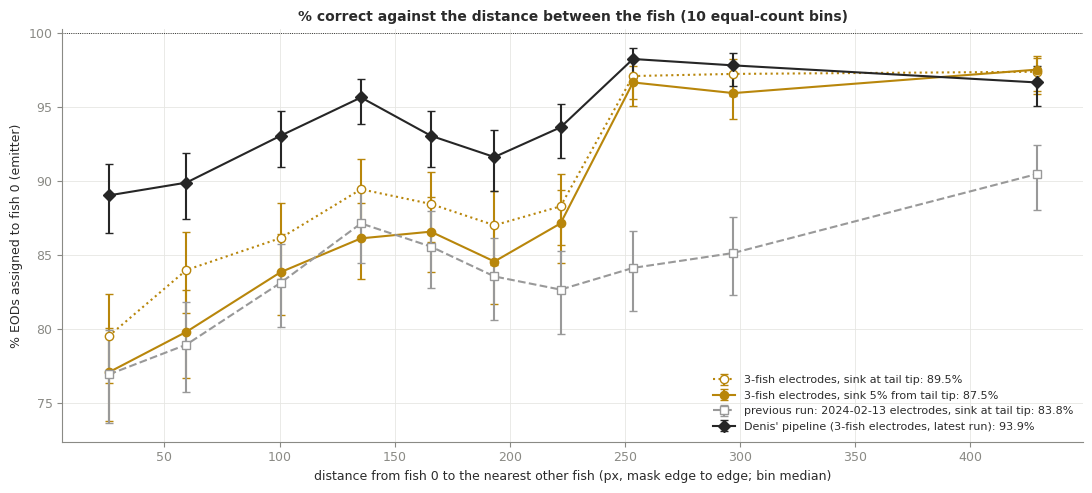

,"3-fish electrodes, sink at tail tip","3-fish electrodes, sink 5% from tail tip","previous run: 2024-02-13 electrodes, sink at tail tip","Denis' pipeline (3-fish electrodes, latest run)"
median gap (px),,,,
26.0,79.5,77.1,76.9,89.0
60.0,84.0,79.8,79.0,89.9
100.0,86.2,83.9,83.1,93.1
135.0,89.5,86.1,87.2,95.7
166.0,88.5,86.6,85.6,93.1
193.0,87.0,84.6,83.6,91.6
222.0,88.3,87.2,82.7,93.7
253.0,97.1,96.7,84.1,98.3
297.0,97.3,96.0,85.2,97.8


In [13]:
def gap_to_others(k):
    '''Smallest distance (px) between the mask of fish 0 and the masks of the other two fish in frame k.'''
    fm = frame_masks(k)
    t = cKDTree(np.argwhere(fm[EMITTER]))
    return min(t.query(np.argwhere(fm[f]))[0].min() for f in FISH if f != EMITTER and fm[f].any())

assigned['gap_px'] = [gap_to_others(int(k)) for k in assigned.frame]
assigned.to_csv(f'{OUT}/eod_assignments_my_pipeline.csv', index_label='row')
print(f"{len(assigned)} EODs -> {OUT}/eod_assignments_my_pipeline.csv")

def wilson(k, m, z=1.96):
    '''95% Wilson interval of k successes in m trials, in %.'''
    p = k / m; c = (p + z ** 2 / (2 * m)) / (1 + z ** 2 / m); hw = z * np.sqrt(p * (1 - p) / m + z ** 2 / (4 * m ** 2)) / (1 + z ** 2 / m)
    return 100 * (c - hw), 100 * (c + hw)

gbins = pd.qcut(assigned.gap_px, 10)
STYLE = dict(zip(fish_cols, [('#B8860B', 'o', ':'), ('#B8860B', 'o', '-'), ('0.6', 's', '--'), ('0.15', 'D', '-')]))
fig, ax = plt.subplots(figsize=(11, 5))
curves = {}
for c in fish_cols:
    g = assigned.groupby(gbins, observed=True)
    t = pd.DataFrame({'median gap (px)': g.gap_px.median(), 'n': g.size(), 'n correct': g[c].apply(lambda s: (s == EMITTER).sum())})
    t['% correct'] = 100 * t['n correct'] / t.n; t['lo'], t['hi'] = wilson(t['n correct'], t.n)
    curves[c.replace('fish | ', '')] = t['% correct'].to_numpy()
    col, mk, ls = STYLE[c]
    ax.errorbar(t['median gap (px)'], t['% correct'], yerr=[t['% correct'] - t.lo, t.hi - t['% correct']], fmt=mk, ls=ls, color=col,
                mfc=col if ls == '-' else 'white', capsize=3,
                label=f"{c.replace('fish | ', '')}: {100 * (assigned[c] == EMITTER).mean():.1f}%")
ax.axhline(100, color='k', lw=0.6, ls=':')
ax.set(xlabel='distance from fish 0 to the nearest other fish (px, mask edge to edge; bin median)',
       ylabel='% EODs assigned to fish 0 (emitter)', title='% correct against the distance between the fish (10 equal-count bins)')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); fig.savefig(f'{OUT}/figures/correct_vs_distance.png', dpi=110); plt.show()
display(pd.DataFrame(curves, index=pd.Index(t['median gap (px)'].round(0).to_numpy(), name='median gap (px)')).round(1))

### Over the recording

% of EODs assigned to fish 0 in 30 time bins with equal numbers of EODs (about 230 each), for every pipeline; error bars: 95% Wilson interval.

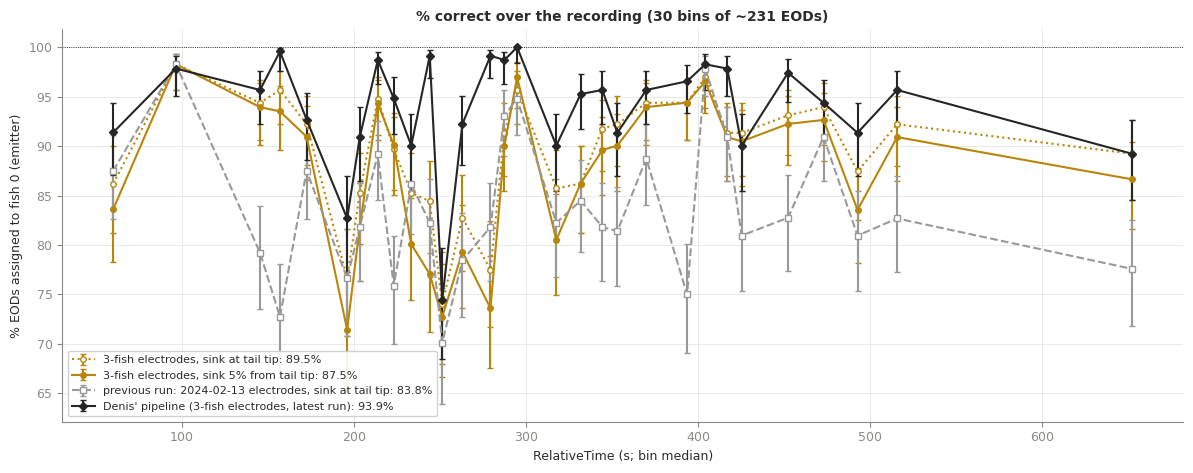

In [14]:
tb = pd.qcut(assigned.time, 30)
fig, ax = plt.subplots(figsize=(12, 4.8))
for c in fish_cols:
    g = assigned.groupby(tb, observed=True)
    t = pd.DataFrame({'t': g.time.median(), 'n': g.size(), 'k': g[c].apply(lambda s: (s == EMITTER).sum())})
    t['pct'] = 100 * t.k / t.n; lo, hi = wilson(t.k, t.n)
    col, mk, ls = STYLE[c]
    ax.errorbar(t.t, t.pct, yerr=[t.pct - lo, hi - t.pct], fmt=mk, ls=ls, color=col, mfc=col if ls == '-' else 'white', ms=4, capsize=2,
                label=f"{c.replace('fish | ', '')}: {100 * (assigned[c] == EMITTER).mean():.1f}%")
ax.axhline(100, color='k', lw=0.6, ls=':')
ax.set(xlabel='RelativeTime (s; bin median)', ylabel='% EODs assigned to fish 0 (emitter)',
       title=f'% correct over the recording (30 bins of ~{len(assigned) // 30} EODs)')
ax.legend(fontsize=8, loc='lower left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/assignment_over_time.png', dpi=110); plt.show()

## 7. Summary

6,938 EODs in the 6,879 frames that pass the mask QC and are in `3_fish_good_frames_sleap.csv`; the emitter is fish 0 (smallest, SLEAP C). Shape-only rule.

| pipeline | % fish 0 (correct) | % fish 1 | % fish 2 |
|---|---|---|---|
| **3-fish electrodes, sink at tail tip** | **89.5** | 3.5 | 7.0 |
| 3-fish electrodes, sink 5% from tail tip | 87.5 | 4.1 | 8.3 |
| previous run: 2024-02-13 electrodes, sink at tail tip | 83.8 | 6.1 | 10.1 |
| Denis' pipeline, latest run (3-fish electrodes, no refractory) | 93.9 | 2.4 | 3.8 |

- The 3-fish electrode file (pairs 2 and 5 flipped) raises % correct from 83.8 to 89.5 at the same sink: the polarity check was right for this recording.
- Sink at the tail tip is better than 5% in: 89.5 vs 87.5 (the two agree on 97.2% of EODs; of the 196 EODs where they disagree, 108 + 54 go from fish 0 to another fish when the sink moves in, 28 the other way).
- Denis' latest run is 4.4 points ahead: he is right on 407 EODs where mine (sink at tail tip) is wrong, mine is right on 101 where his is wrong, both are wrong on 323. The gap comes from frames where the fish are close: fish 0 < 120 px from the nearest fish, 80–86% (mine) vs 89–93% (Denis); 120–240 px, 87–90% vs 92–96%; ≥ 240 px, both 97–98%.
- The `discharging_fish` column inside `Assigned_Data_3fish_...csv` is an older output of Denis' pipeline (90.2% on these EODs); it is not used here.
